# Курсовая работа: распределение Райса

Порядок разделов:
1. Подключение библиотек и чтение данных.
2. Описательные статистики.
3. Эмпирическая функция распределения.
4. Гистограммы.
5. Распределение Райса и смысл параметров.
6. Метод моментов.
7. Метод максимального правдоподобия.
8. Сравнение функций распределения.
9. Информация Фишера и приближённая эффективность.
10. Статистика Колмогорова; границы интервалов для критерия χ².
11. Моделирование нормальной выборки.

SciPy используется для специальных функций, интегралов
и численной оптимизации.

## 1. Библиотеки и исходная выборка
Все импорты находятся здесь. Данные читаем один раз и дальше используем список `sample`.

In [1]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from scipy.integrate import quad
from scipy.optimize import brentq, minimize
from scipy.special import i0e, i1e
from scipy.stats import norm, rice


DATA_FILE = Path("var_6_rice.csv")
OUTPUT_DIR = Path("output") / "notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Единое оформление всех рисунков.
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.constrained_layout.use": True,
})

In [2]:
def read_sample(filename):
    """Читает файл, в котором каждое число записано на отдельной строке."""
    sample = []

    with open(filename, "r", encoding="utf-8-sig") as file:
        for line in file:
            if line.strip():
                sample.append(float(line))

    if len(sample) < 2:
        raise ValueError("Для расчётов нужны хотя бы два наблюдения.")
    for value in sample:
        if not math.isfinite(value) or value <= 0:
            raise ValueError("В этой работе нужны конечные положительные значения.")

    return sample


sample = read_sample(DATA_FILE)
n = len(sample)
print("Объём выборки:", n)
print("Первые 10 элементов:", sample[:10])

Объём выборки: 300
Первые 10 элементов: [14.532042, 14.525097, 13.11719, 16.164978, 13.681264, 13.950186, 14.854287, 15.685266, 16.112069, 15.789271]


## 2. Описательные статистики
Каждая функция получает выборку как аргумент и возвращает результат через `return`.
`len(sample)` — число наблюдений, а `sorted(sample)` — новая отсортированная копия.
Для расчётов ниже предполагаем, что выборка содержит не менее двух чисел.

### 2.1. Сумма, среднее и медиана
При чётном объёме медиана равна среднему двух центральных элементов.

In [3]:
def sample_sum(sample):
    """Сумма всех элементов выборки."""
    total = 0
    for value in sample:
        total = total + value

    return total

In [4]:
def sample_mean(sample):
    """Среднее: сумма наблюдений, делённая на их количество."""
    total = sample_sum(sample)
    mean = total / len(sample)

    return mean

In [5]:
def sample_median(sample):
    """Центральное значение упорядоченной выборки."""
    sorted_sample = sorted(sample)
    n = len(sorted_sample)

    if n % 2 == 1:
        median = sorted_sample[n // 2]
    else:
        left = sorted_sample[n // 2 - 1]
        right = sorted_sample[n // 2]
        median = (left + right) / 2

    return median

### 2.2. Мода и размах
Мода — наиболее частое значение. Если несколько значений делят максимум частоты,
выводим их все. Если все значения встречаются по одному разу, выделенной моды нет.
Размах — разность между максимумом и минимумом.

In [6]:
def sample_mode(sample):
    """Возвращает список самых частых значений и их частоту."""
    frequencies = {}
    for value in sample:
        if value in frequencies:
            frequencies[value] = frequencies[value] + 1
        else:
            frequencies[value] = 1

    max_frequency = 0
    for frequency in frequencies.values():
        if frequency > max_frequency:
            max_frequency = frequency

    modes = []
    if max_frequency > 1:
        for value in frequencies:
            if frequencies[value] == max_frequency:
                modes.append(value)

    return sorted(modes), max_frequency

In [7]:
def sample_range(sample):
    sorted_sample = sorted(sample)

    min_value = sorted_sample[0]
    max_value = sorted_sample[-1]

    result_range = max_value - min_value

    return result_range

### 2.3. Дисперсии и моменты
Смещённая дисперсия делит сумму квадратов отклонений на $n$, исправленная
(несмещённая) — на $n-1$.

Начальный момент порядка $k$: $m_k = \frac{1}{n}\sum x_i^k$.
Центральный момент: $\mu_k = \frac{1}{n}\sum(x_i-\bar{x})^k$.
Для задания выбираем $k=3$.

In [8]:
def biased_variance(sample):
    mean = sample_mean(sample)
    total = 0

    for value in sample:
        total = total + (value - mean) ** 2

    variance = total / len(sample)

    return variance

In [9]:
def unbiased_variance(sample):
    mean = sample_mean(sample)
    total = 0

    for value in sample:
        total = total + (value - mean) ** 2

    variance = total / (len(sample) - 1)

    return variance

In [10]:
def initial_moment(sample, k):
    total = 0

    for value in sample:
        total = total + value ** k

    moment = total / len(sample)

    return moment

In [11]:
def central_moment(sample, k):
    mean = sample_mean(sample)
    total = 0

    for value in sample:
        total = total + (value - mean) ** k

    moment = total / len(sample)

    return moment

In [12]:
print(f"Сумма элементов: {sample_sum(sample):.6f}")
print(f"Выборочное среднее: {sample_mean(sample):.6f}")
print(f"Медиана: {sample_median(sample):.6f}")

modes, mode_frequency = sample_mode(sample)
if modes:
    print("Мода (или моды):", modes)
else:
    print("Выделенной моды нет: все значения встречаются один раз.")
print("Максимальная частота:", mode_frequency)

print(f"Размах: {sample_range(sample):.6f}")
print(f"Смещённая дисперсия: {biased_variance(sample):.6f}")
print(f"Несмещённая дисперсия: {unbiased_variance(sample):.6f}")

k = 3
print(f"Начальный момент порядка {k}: {initial_moment(sample, k):.6f}")
print(f"Центральный момент порядка {k}: {central_moment(sample, k):.6f}")

Сумма элементов: 4384.225473
Выборочное среднее: 14.614085
Медиана: 14.528569
Выделенной моды нет: все значения встречаются один раз.
Максимальная частота: 1
Размах: 4.968461
Смещённая дисперсия: 0.943927
Несмещённая дисперсия: 0.947084
Начальный момент порядка 3: 3162.602404
Центральный момент порядка 3: 0.066788


## 3. Эмпирическая функция распределения
Используем соглашение $F_n(x)=\#\{x_i\leq x\}/n$: функция показывает долю
наблюдений, не превышающих $x$. Перед первым наблюдением она равна 0,
после последнего — 1. При совпадающих наблюдениях скачок сразу учитывает все повторы.

Подвыборки берём без возвращения внутри каждой подвыборки. Между разными
подвыборками наблюдения могут повторяться. Фиксируем генератор для повторяемости.

In [13]:
def empirical_distribution(sample):
    """Координаты скачков эмпирической функции, с учётом повторов."""
    sorted_sample = sorted(sample)
    x_values = []
    probabilities = []

    for i in range(len(sorted_sample)):
        value = sorted_sample[i]
        if i == len(sorted_sample) - 1 or value != sorted_sample[i + 1]:
            x_values.append(value)
            probabilities.append((i + 1) / len(sorted_sample))

    return x_values, probabilities


def plot_empirical(sample, label, color="black"):
    """Добавляет ступенчатую линию на текущий рисунок."""
    x_values, probabilities = empirical_distribution(sample)
    padding = max(sample_range(sample) * 0.05, 0.1)

    # Добавляем горизонтальные участки до и после наблюдений.
    x_values = [min(sample) - padding] + x_values + [max(sample) + padding]
    probabilities = [0] + probabilities + [1]
    plt.step(x_values, probabilities, where="post", color=color, label=label)


subsample_sizes = [10, 100, 200]
if n < max(subsample_sizes):
    raise ValueError("Для подвыборок из задания нужно не менее 200 наблюдений.")

subsample_generator = random.Random(42)
subsamples = []
for size in subsample_sizes:
    subsamples.append(subsample_generator.sample(sample, size))

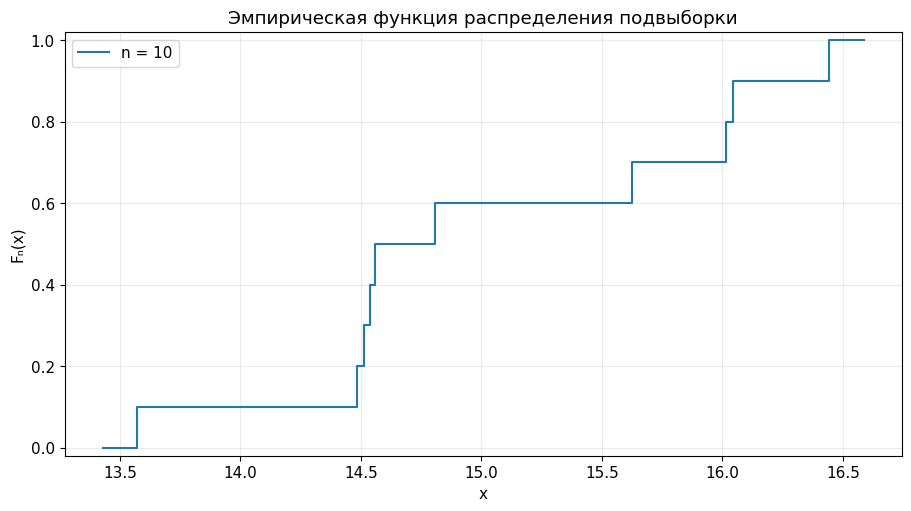

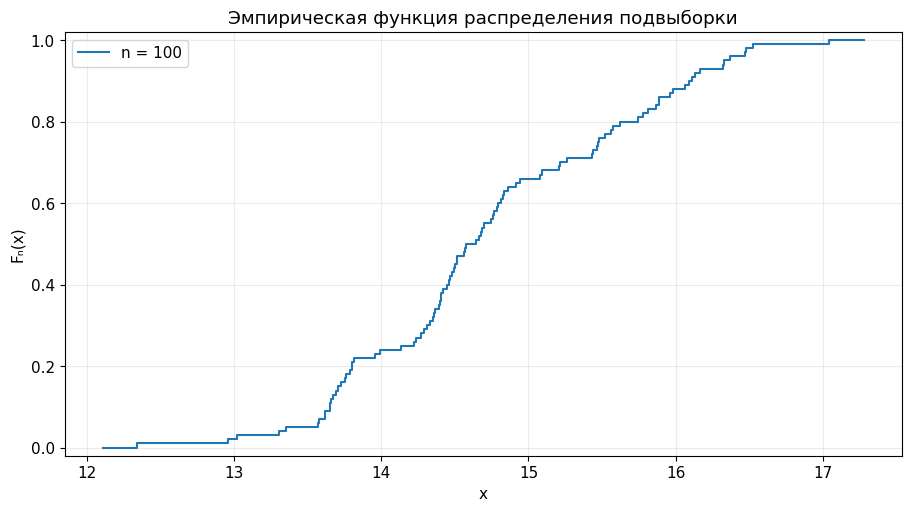

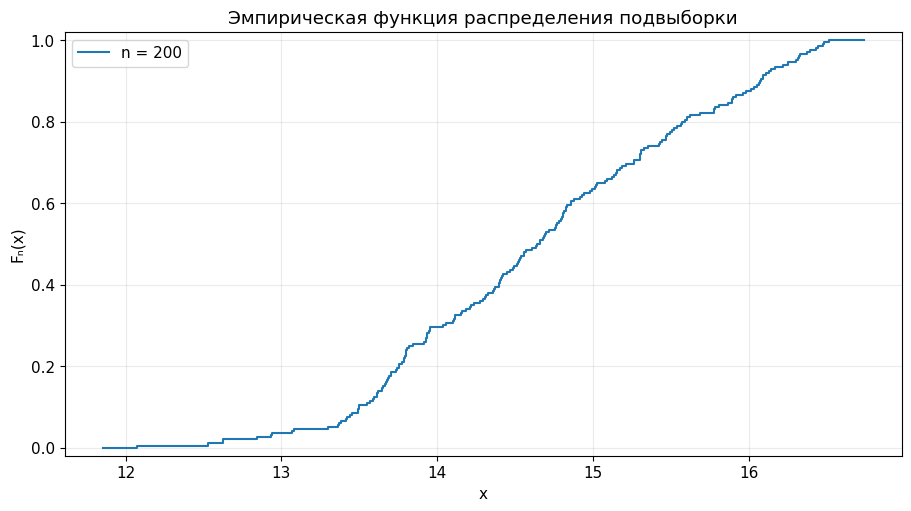

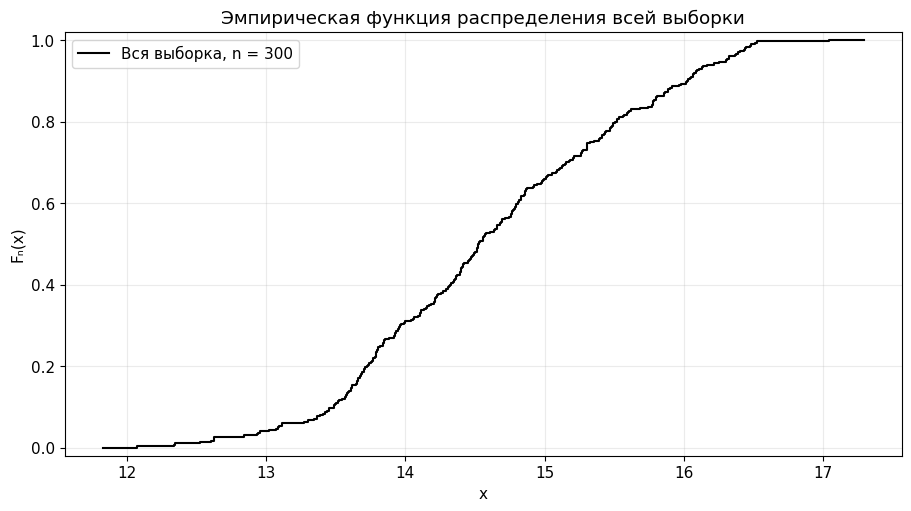

In [14]:
for subsample in subsamples:
    plt.figure()
    plot_empirical(subsample, label=f"n = {len(subsample)}", color="tab:blue")
    plt.title("Эмпирическая функция распределения подвыборки")
    plt.xlabel("x")
    plt.ylabel("Fₙ(x)")
    plt.ylim(-0.02, 1.02)
    plt.legend()
    plt.show()

plt.figure()
plot_empirical(sample, label=f"Вся выборка, n = {n}")
plt.title("Эмпирическая функция распределения всей выборки")
plt.xlabel("x")
plt.ylabel("Fₙ(x)")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

## 4. Гистограммы
Разбиваем диапазон на равные интервалы и вручную считаем число попаданий.
Левая граница входит в интервал, правая — нет; последний интервал включает максимум.
Здесь высота столбца — **частота**, а не плотность. Используем те же подвыборки,
что и в предыдущем разделе.

In [15]:
def histogram_data(sample, intervals_count):
    if intervals_count < 1:
        raise ValueError("Число интервалов должно быть положительным.")

    min_value = min(sample)
    max_value = max(sample)

    if min_value == max_value:
        return [min_value - 0.5], [len(sample)], 1.0

    interval_width = (max_value - min_value) / intervals_count

    intervals = []
    frequencies = []

    for i in range(intervals_count):
        left = min_value + i * interval_width

        intervals.append(left)
        frequencies.append(0)

    for value in sample:
        index = int((value - min_value) / interval_width)

        if index == intervals_count:
            index = intervals_count - 1

        frequencies[index] = frequencies[index] + 1

    return intervals, frequencies, interval_width

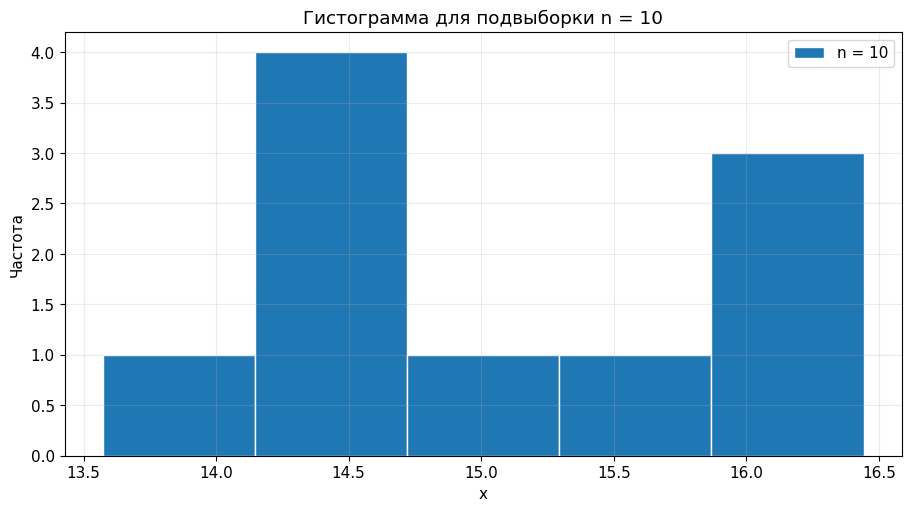

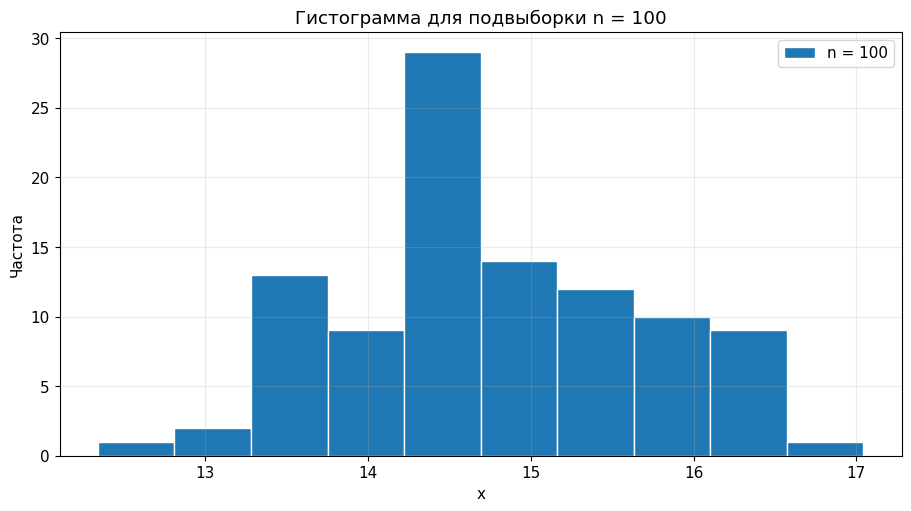

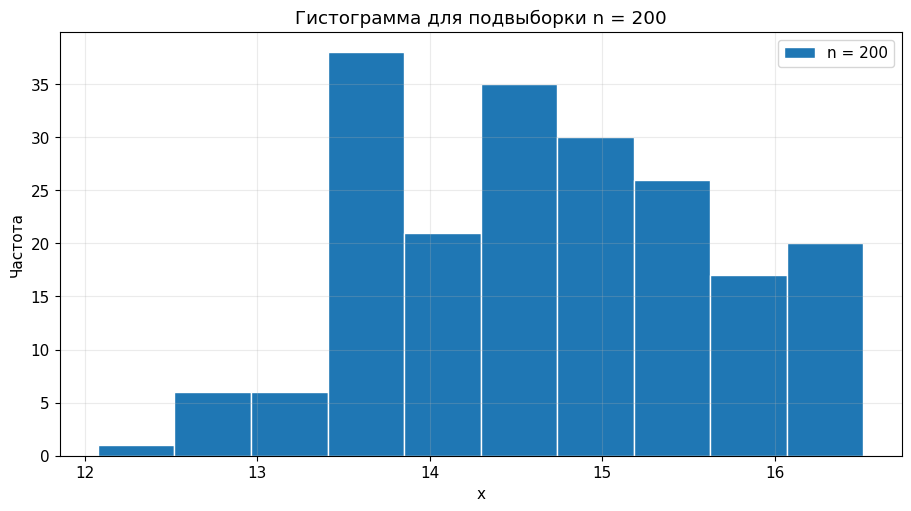

In [16]:
def plot_histogram(sample, intervals_count, title):
    intervals, frequencies, width = histogram_data(sample, intervals_count)

    plt.figure()
    plt.bar(
        intervals, frequencies, width=width, align="edge",
        edgecolor="white", color="tab:blue", label=f"n = {len(sample)}",
    )
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("Частота")
    plt.legend()
    plt.show()


for subsample in subsamples:
    intervals_count = 5 if len(subsample) == 10 else 10
    plot_histogram(
        subsample, intervals_count,
        f"Гистограмма для подвыборки n = {len(subsample)}",
    )

## 5. Распределение Райса и его параметры
Если $U$ и $V$ независимы, $U\sim N(\nu,\sigma^2)$ и $V\sim N(0,\sigma^2)$,
то $R=\sqrt{U^2+V^2}$ имеет распределение Райса.

- $\nu\geq0$ — расстояние от начала координат до центра двумерного нормального распределения.
- $\sigma>0$ — стандартное отклонение каждой нормальной компоненты.
  Это **не** стандартное отклонение самой величины $R$.

Плотность:
$$f(x)=\frac{x}{\sigma^2}\exp\left(-\frac{x^2+\nu^2}{2\sigma^2}\right)
I_0\left(\frac{x\nu}{\sigma^2}\right),\quad x\geq0.$$

В коде используем `i0e(z) = exp(-|z|) * I₀(z)`, чтобы избежать слишком больших
промежуточных чисел. Функцию распределения считаем методом трапеций:
приближённо складываем площади под графиком плотности.

In [17]:
def rice_density(x, nu, sigma):
    if nu < 0 or sigma <= 0:
        raise ValueError("Нужно nu >= 0 и sigma > 0.")
    if x < 0:
        return 0

    z = x * nu / sigma ** 2

    density = (
        x / sigma ** 2
        * math.exp(
            -((x - nu) ** 2) / (2 * sigma ** 2)
        )
        * i0e(z)
    )

    return density


def theoretical_rice_distribution(nu, sigma, x_max, points_count):
    x_values = []
    y_values = []

    step = x_max / points_count
    current_sum = 0

    previous_x = 0
    previous_density = rice_density(previous_x, nu, sigma)

    x_values.append(0)
    y_values.append(0)

    for i in range(1, points_count + 1):
        current_x = i * step
        current_density = rice_density(current_x, nu, sigma)

        current_sum = current_sum + (previous_density + current_density) * step / 2

        x_values.append(current_x)
        y_values.append(current_sum)

        previous_x = current_x
        previous_density = current_density

    return x_values, y_values

### 5.1. Геометрическая иллюстрация
Круг показывает масштаб σ вокруг центра. Он не является границей всех возможных значений.

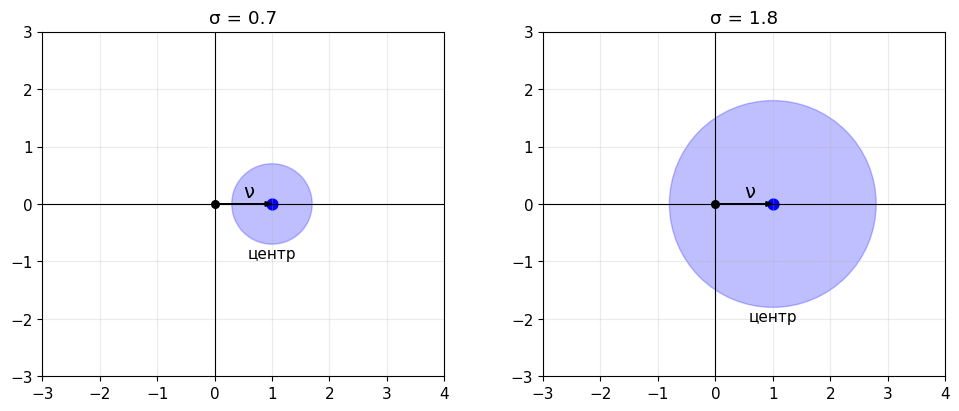

In [18]:
def draw_sigma_interpretation(ax, nu, sigma, title):
    center = (nu, 0)

    circle = patches.Circle(center, sigma, color="blue", alpha=0.25)
    ax.add_patch(circle)

    ax.scatter([0], [0], color="black", s=30)
    ax.scatter([center[0]], [center[1]], color="blue", s=60)

    ax.arrow(0, 0, nu, 0, head_width=0.08, length_includes_head=True, color="black")
    ax.text(nu / 2, 0.12, "ν", fontsize=14)

    ax.text(center[0], center[1] - sigma - 0.25, "центр", ha="center")
    ax.set_title(title)

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)

    ax.set_xlim(-3, nu + 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect("equal")
    ax.grid(True)


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

draw_sigma_interpretation(axes[0], nu=1, sigma=0.7, title="σ = 0.7")
draw_sigma_interpretation(axes[1], nu=1, sigma=1.8, title="σ = 1.8")

plt.show()

### 5.2. Влияние параметров на функцию распределения

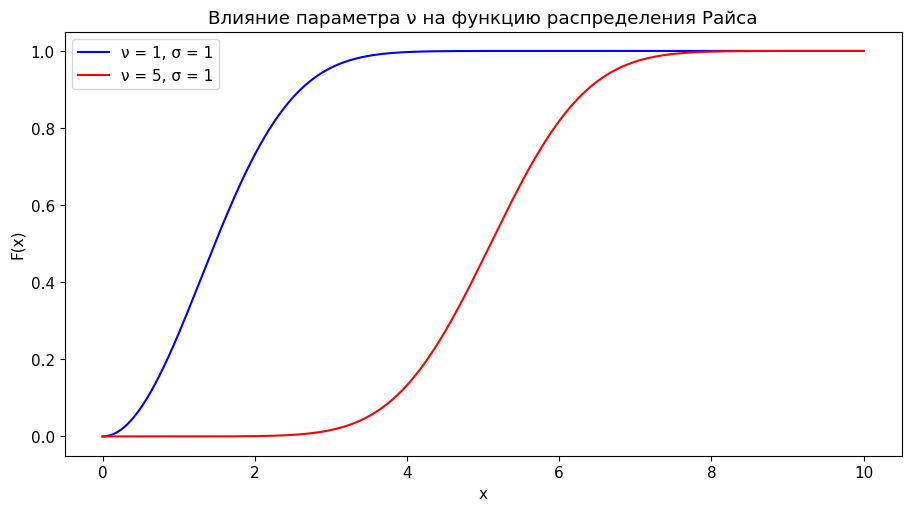

In [19]:
sigma_example = 1

x_1, y_1 = theoretical_rice_distribution(1, sigma_example, 10, 1000)
x_2, y_2 = theoretical_rice_distribution(5, sigma_example, 10, 1000)

plt.figure()
plt.plot(x_1, y_1, label="ν = 1, σ = 1", color="blue")
plt.plot(x_2, y_2, label="ν = 5, σ = 1", color="red")

plt.title("Влияние параметра ν на функцию распределения Райса")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.legend()
plt.grid()

plt.show()

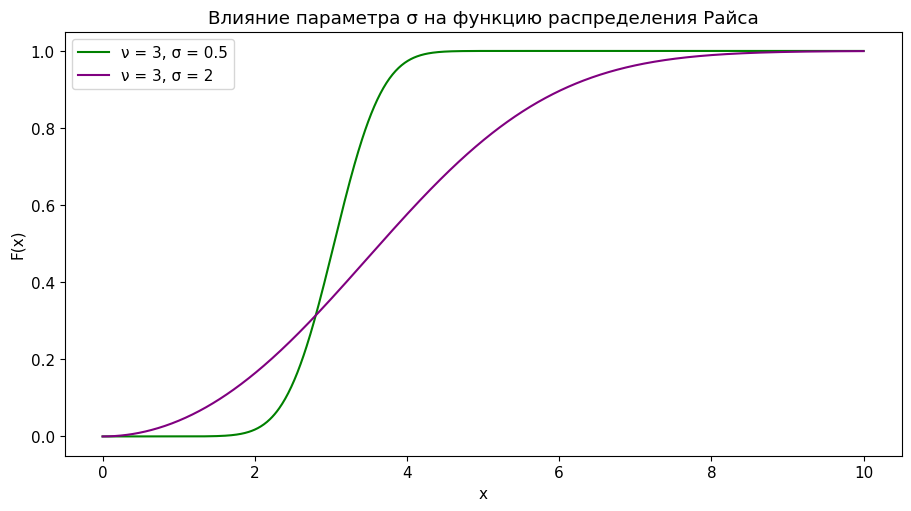

In [20]:
nu_example = 3

x_1, y_1 = theoretical_rice_distribution(nu_example, 0.5, 10, 1000)
x_2, y_2 = theoretical_rice_distribution(nu_example, 2, 10, 1000)

plt.figure()
plt.plot(x_1, y_1, label="ν = 3, σ = 0.5", color="green")
plt.plot(x_2, y_2, label="ν = 3, σ = 2", color="purple")

plt.title("Влияние параметра σ на функцию распределения Райса")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.legend()
plt.grid()

plt.show()

## 6. Оценки методом моментов
Приравниваем **первый и второй начальные** теоретические моменты
соответствующим выборочным моментам $a_1$ и $a_2$:
$$E(R;\nu,\sigma)=a_1,\qquad \nu^2+2\sigma^2=a_2.$$
Первый теоретический момент содержит функции Бесселя $I_0$ и $I_1$.
Из второго уравнения выражаем $\sigma=\sqrt{(a_2-\nu^2)/2}$,
подставляем в первое и численно находим корень по $\nu$.


In [21]:
moment_1 = initial_moment(sample, 1)
moment_2 = initial_moment(sample, 2)

def theoretical_rice_mean(nu, sigma):
    """Первый теоретический начальный момент Райса."""
    z = nu ** 2 / (4 * sigma ** 2)
    return sigma * math.sqrt(math.pi / 2) * (
        (1 + 2 * z) * i0e(z) + 2 * z * i1e(z)
    )

def sigma_from_nu(nu):
    return math.sqrt((moment_2 - nu ** 2) / 2)

def first_moment_difference(nu):
    return theoretical_rice_mean(nu, sigma_from_nu(nu)) - moment_1

# Верхняя граница чуть меньше sqrt(moment_2), чтобы sigma оставалась положительной.
upper_nu = math.sqrt(moment_2) * (1 - 1e-8)
if first_moment_difference(0) * first_moment_difference(upper_nu) >= 0:
    raise ValueError("Не найдено внутреннее решение моментных уравнений.")

nu_moments = brentq(first_moment_difference, 0, upper_nu)
sigma_moments = sigma_from_nu(nu_moments)

print(f"Начальный момент 1-го порядка: {moment_1:.8f}")
print(f"Начальный момент 2-го порядка: {moment_2:.8f}")
print(f"Оценка ν методом моментов: {nu_moments:.6f}")
print(f"Оценка σ методом моментов: {sigma_moments:.6f}")
print(f"Проверка E[R]: {theoretical_rice_mean(nu_moments, sigma_moments):.8f}")
print(f"Проверка E[R²]: {nu_moments ** 2 + 2 * sigma_moments ** 2:.8f}")

Начальный момент 1-го порядка: 14.61408491
Начальный момент 2-го порядка: 214.51540516
Оценка ν методом моментов: 14.581609
Оценка σ методом моментов: 0.972647
Проверка E[R]: 14.61408491
Проверка E[R²]: 214.51540516


## 7. Метод максимального правдоподобия (ММП)
Ищем параметры, при которых наблюдаемая выборка имеет наибольшую плотность
правдоподобия. Вместо произведения плотностей используем сумму их логарифмов.
`minimize` ищет минимум, поэтому меняем знак суммы.

Оптимизируем $\log\sigma$, чтобы после обратного преобразования $\sigma$ оставалась
положительной. Стартуем с оценок метода моментов и проверяем успешность оптимизации.

In [22]:
def negative_log_likelihood(parameters, sample):
    nu = parameters[0]
    log_sigma = parameters[1]

    # Такая замена гарантирует, что sigma > 0
    sigma = math.exp(log_sigma)

    log_likelihood = 0

    for value in sample:
        z = value * nu / sigma ** 2

        # Устойчивое вычисление ln(I0(z))
        log_bessel = z + math.log(i0e(z))

        log_density = (
            math.log(value)
            - 2 * math.log(sigma)
            - (value ** 2 + nu ** 2) / (2 * sigma ** 2)
            + log_bessel
        )

        log_likelihood = log_likelihood + log_density

    # minimize ищет минимум,
    # поэтому возвращаем значение с противоположным знаком
    return -log_likelihood


# Начальные значения параметров

initial_parameters = [
    nu_moments,
    math.log(sigma_moments)
]


# Численный поиск оценок

result = minimize(
    negative_log_likelihood,
    initial_parameters,
    args=(sample,),
    method="L-BFGS-B",
    bounds=[
        (0, None),      # nu >= 0
        (None, None)    # log_sigma может быть любым
    ]
)


if not result.success:
    raise RuntimeError(f"Оптимизация не сошлась: {result.message}")

# Получение найденных параметров

nu_likelihood = result.x[0]
sigma_likelihood = math.exp(result.x[1])


print("Оценка ν методом моментов:", nu_moments)
print("Оценка σ методом моментов:", sigma_moments)
print("Оценка ν методом максимального правдоподобия:", nu_likelihood)
print("Оценка σ методом максимального правдоподобия:", sigma_likelihood)
print("Минимум отрицательного логарифма правдоподобия:", result.fun)

Оценка ν методом моментов: 14.581609036533246
Оценка σ методом моментов: 0.9726466639002356
Оценка ν методом максимального правдоподобия: 14.581609036533246
Оценка σ методом максимального правдоподобия: 0.9726466639002352
Минимум отрицательного логарифма правдоподобия: 417.0241534572217


## 8. Сравнение эмпирической и теоретических функций
Сначала строим сравнения для каждого метода отдельно, затем общий рисунок.
Для метода моментов используем собственное интегрирование из раздела 5,
для ММП и общего рисунка — `rice.cdf`. В SciPy параметр `b` равен `ν / σ`,
а `scale` равен `σ`. Все оценки берём из расчётов выше, без ручной подстановки.

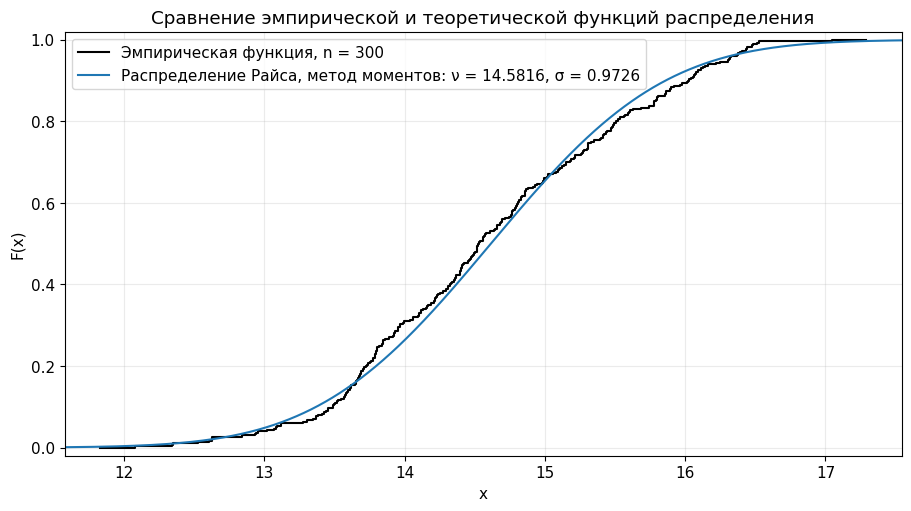

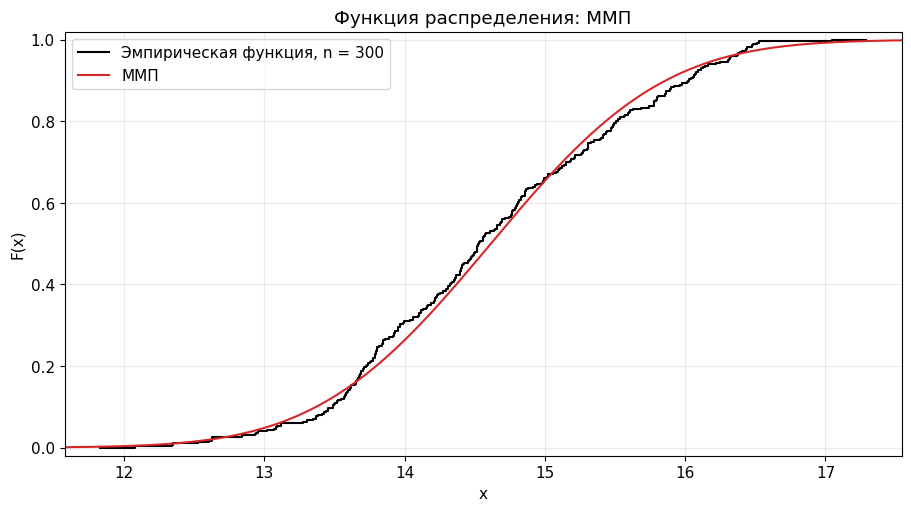

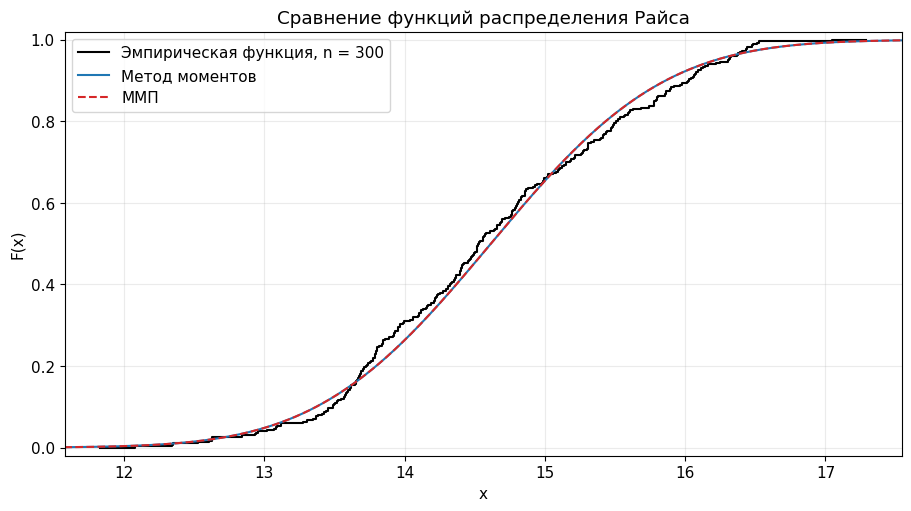

In [23]:
x_max = max(sample) + 3 * max(sigma_moments, sigma_likelihood)
moments_x, moments_cdf = theoretical_rice_distribution(
    nu_moments, sigma_moments, x_max, 20000,
)
x_grid = np.linspace(0, x_max, 2000)
cdf_moments = rice.cdf(x_grid, b=nu_moments / sigma_moments, scale=sigma_moments)
cdf_likelihood = rice.cdf(
    x_grid, b=nu_likelihood / sigma_likelihood, scale=sigma_likelihood,
)


def finish_cdf_plot(title):
    """Общие подписи и границы для рисунков этого раздела."""
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("F(x)")
    plt.xlim(min(sample) - 0.5, max(sample) + 0.5)
    plt.ylim(-0.02, 1.02)
    plt.legend()


plt.figure()
plot_empirical(sample, label=f"Эмпирическая функция, n = {n}")
plt.plot(
    moments_x, moments_cdf, color="tab:blue",
    label=f"Распределение Райса, метод моментов: ν = {nu_moments:.4f}, σ = {sigma_moments:.4f}",
)
finish_cdf_plot("Сравнение эмпирической и теоретической функций распределения")
plt.savefig(OUTPUT_DIR / "Сравнение ЭФР и Райса — метод моментов.png", dpi=300)
plt.show()

plt.figure()
plot_empirical(sample, label=f"Эмпирическая функция, n = {n}")
plt.plot(x_grid, cdf_likelihood, color="tab:red", label="ММП")
finish_cdf_plot("Функция распределения: ММП")
plt.show()

plt.figure()
plot_empirical(sample, label=f"Эмпирическая функция, n = {n}")
plt.plot(x_grid, cdf_moments, color="tab:blue", label="Метод моментов")
plt.plot(x_grid, cdf_likelihood, "--", color="tab:red", label="ММП")
finish_cdf_plot("Сравнение функций распределения Райса")
plt.savefig(OUTPUT_DIR / "Итоговый график функций распределения.png", dpi=300)
plt.show()

## 9. Информация Фишера и приближённая эффективность метода моментов
Этот раздел сложнее остальных: здесь используется математический анализ.
Функции `score_nu` и `score_sigma` — производные логарифма плотности по параметрам.
Интегралы от их произведений дают элементы матрицы информации Фишера
**для одного наблюдения**. Поскольку неизвестны оба параметра, учитываем
и внедиагональный элемент этой матрицы.

Ниже подставляем оценки метода моментов вместо неизвестных истинных параметров.
Дисперсии оценок вычисляем приближённо, дельта-методом. Отношение границы
Рао–Крамера к такой дисперсии трактуем как **оценку асимптотической эффективности**.
Это не доказательство несмещённости и не точная конечновыборочная эффективность:
обычная граница Рао–Крамера относится к несмещённым оценкам при условиях регулярности.

In [24]:
def score_nu(x, nu, sigma):
    z = x * nu / sigma ** 2

    bessel_ratio = i1e(z) / i0e(z)

    result = (
        x * bessel_ratio - nu
    ) / sigma ** 2

    return result

def score_sigma(x, nu, sigma):
    z = x * nu / sigma ** 2

    bessel_ratio = i1e(z) / i0e(z)

    result = (
        -2 / sigma
        + (
            x ** 2
            + nu ** 2
            - 2 * x * nu * bessel_ratio
        ) / sigma ** 3
    )

    return result

def integrand_nu_nu(x, nu, sigma):
    density = rice_density(x, nu, sigma)
    score = score_nu(x, nu, sigma)

    return score ** 2 * density


def integrand_sigma_sigma(x, nu, sigma):
    density = rice_density(x, nu, sigma)
    score = score_sigma(x, nu, sigma)

    return score ** 2 * density


def integrand_nu_sigma(x, nu, sigma):
    density = rice_density(x, nu, sigma)
    first_score = score_nu(x, nu, sigma)
    second_score = score_sigma(x, nu, sigma)

    return first_score * second_score * density

In [25]:
nu = nu_moments
sigma = sigma_moments

information_nu_nu = quad(
    integrand_nu_nu,
    0,
    math.inf,
    args=(nu, sigma),
)[0]

information_sigma_sigma = quad(
    integrand_sigma_sigma,
    0,
    math.inf,
    args=(nu, sigma),
)[0]

information_nu_sigma = quad(
    integrand_nu_sigma,
    0,
    math.inf,
    args=(nu, sigma),
)[0]

print("I_nu_nu =", information_nu_nu)
print("I_sigma_sigma =", information_sigma_sigma)
print("I_nu_sigma =", information_nu_sigma)

effective_information_nu = (
    information_nu_nu
    - information_nu_sigma ** 2
    / information_sigma_sigma
)

effective_information_sigma = (
    information_sigma_sigma
    - information_nu_sigma ** 2
    / information_nu_nu
)

cramer_rao_nu = (
    1 / (n * effective_information_nu)
)

cramer_rao_sigma = (
    1 / (n * effective_information_sigma)
)

print("Граница Рао-Крамера для nu:", cramer_rao_nu)
print("Граница Рао-Крамера для sigma:", cramer_rao_sigma)

I_nu_nu = 1.0546791894399705
I_sigma_sigma = 2.1093263926945482
I_nu_sigma = 0.07066644861053323
Граница Рао-Крамера для nu: 0.0031676291746320813
Граница Рао-Крамера для sigma: 0.0015838386045507339


### 9.1. Моменты и производные для дельта-метода
Новый метод моментов использует $a_1$ и $a_2$. Поэтому для их ковариации
нужны теоретические моменты Райса до четвёртого порядка. Матрица $J$ содержит
производные $E(R)$ и $E(R^2)$ по параметрам $\nu$ и $\sigma$.
Производные $E(R)$ вычисляем интегрированием $x$ с соответствующей
производной логарифма плотности (функцией score).

In [26]:
model_moment_1 = theoretical_rice_mean(nu, sigma)
model_moment_2 = nu ** 2 + 2 * sigma ** 2
model_moment_3 = quad(
    lambda x: x ** 3 * rice_density(x, nu, sigma), 0, math.inf
)[0]
model_moment_4 = (
    nu ** 4 + 8 * nu ** 2 * sigma ** 2 + 8 * sigma ** 4
)

covariance_moments = np.array([
    [model_moment_2 - model_moment_1 ** 2,
     model_moment_3 - model_moment_1 * model_moment_2],
    [model_moment_3 - model_moment_1 * model_moment_2,
     model_moment_4 - model_moment_2 ** 2],
])

derivative_mean_nu = quad(
    lambda x: x * score_nu(x, nu, sigma) * rice_density(x, nu, sigma),
    0, math.inf,
)[0]
derivative_mean_sigma = quad(
    lambda x: x * score_sigma(x, nu, sigma) * rice_density(x, nu, sigma),
    0, math.inf,
)[0]
moment_jacobian = np.array([
    [derivative_mean_nu, derivative_mean_sigma],
    [2 * nu, 4 * sigma],
])

### 9.2. Приближённые дисперсии и эффективность
Для новой системы моментных уравнений дельта-метод даёт
$V_{\mathrm{ММ}}\approx J^{-1}\Sigma(J^{-1})^T/n$.
Сравниваем диагональные элементы этой матрицы с границами Рао–Крамера.
Деление на `n` переводит ковариации одного наблюдения в ковариации выборочных моментов.

In [27]:
inverse_jacobian = np.linalg.inv(moment_jacobian)
covariance_estimates = (
    inverse_jacobian @ covariance_moments @ inverse_jacobian.T / n
)
variance_nu_moments = covariance_estimates[0, 0]
variance_sigma_moments = covariance_estimates[1, 1]

efficiency_nu = (
    cramer_rao_nu / variance_nu_moments
)

efficiency_sigma = (
    cramer_rao_sigma / variance_sigma_moments
)

print()
print("Приближённая дисперсия оценки nu:", variance_nu_moments)
print("Граница Рао-Крамера для nu:", cramer_rao_nu)
print("Асимптотическая эффективность оценки nu:", efficiency_nu)
print(f"Асимптотическая эффективность nu: {efficiency_nu * 100:.4f}%")

print()
print("Приближённая дисперсия оценки sigma:", variance_sigma_moments)
print("Граница Рао-Крамера для sigma:", cramer_rao_sigma)
print("Асимптотическая эффективность оценки sigma:", efficiency_sigma)
print(f"Асимптотическая эффективность sigma: {efficiency_sigma * 100:.4f}%")


Приближённая дисперсия оценки nu: 0.0031676291746323957
Граница Рао-Крамера для nu: 0.0031676291746320813
Асимптотическая эффективность оценки nu: 0.9999999999999007
Асимптотическая эффективность nu: 100.0000%

Приближённая дисперсия оценки sigma: 0.0015838386045715271
Граница Рао-Крамера для sigma: 0.0015838386045507339
Асимптотическая эффективность оценки sigma: 0.9999999999868716
Асимптотическая эффективность sigma: 100.0000%


## 10. Статистика Колмогорова
Сравниваем эмпирическую функцию с моделью, параметры которой найдены методом ММП:
$$D^+=\max_i\left(\frac{i}{n}-F(x_{(i)})\right),\qquad
D^-=\max_i\left(F(x_{(i)})-\frac{i-1}{n}\right),\qquad D=\max(D^+,D^-).$$



In [28]:
# Оценки параметров, полученные методом ММП
nu = nu_likelihood
sigma = sigma_likelihood

# В scipy параметр b равен nu / sigma
b = nu / sigma


# Сортируем выборку
sample_sorted = sorted(sample)
n = len(sample_sorted)


# Начальные значения максимумов
d_plus = 0
d_minus = 0

# Здесь запомним номера элементов,
# на которых достигаются максимумы
index_d_plus = 0
index_d_minus = 0

# Значения теоретической функции в точках максимумов
theoretical_d_plus = 0
theoretical_d_minus = 0


# Перебираем все элементы выборки
for i in range(n):
    x = sample_sorted[i]

    # Теоретическая функция распределения Райса
    theoretical_probability = rice.cdf(
        x,
        b=b,
        scale=sigma
    )

    # В Python нумерация начинается с нуля,
    # поэтому математический номер элемента равен i + 1
    empirical_after = (i + 1) / n
    empirical_before = i / n

    # Вычисляем две разности
    current_d_plus = (
        empirical_after - theoretical_probability
    )

    current_d_minus = (
        theoretical_probability - empirical_before
    )

    # Проверяем максимум D+
    if current_d_plus > d_plus:
        d_plus = current_d_plus
        index_d_plus = i
        theoretical_d_plus = theoretical_probability

    # Проверяем максимум D-
    if current_d_minus > d_minus:
        d_minus = current_d_minus
        index_d_minus = i
        theoretical_d_minus = theoretical_probability


# Итоговая статистика Колмогорова
d_observed = max(d_plus, d_minus)

# Ориентировочный порог для полностью заданного распределения
d_critical = 1.36 / math.sqrt(n)


print("Количество элементов:", n)

print()
print("Вычисление D+")
print("Номер элемента:", index_d_plus + 1)
print("Значение элемента:", sample_sorted[index_d_plus])
print(
    "Эмпирическая функция:",
    (index_d_plus + 1) / n
)
print(
    "Теоретическая функция:",
    theoretical_d_plus
)
print("D+ =", d_plus)

print()
print("Вычисление D-")
print("Номер элемента:", index_d_minus + 1)
print("Значение элемента:", sample_sorted[index_d_minus])
print(
    "Эмпирическая функция перед скачком:",
    index_d_minus / n
)
print(
    "Теоретическая функция:",
    theoretical_d_minus
)
print("D- =", d_minus)

print()
print("D наблюдаемое =", d_observed)
print("Ориентировочный порог =", d_critical)

print()

if d_observed < d_critical:
    print("D меньше ориентировочного порога для полностью заданной модели.")
else:
    print("D не меньше ориентировочного порога для полностью заданной модели.")
print("Для решения на уровне 0.05 нужна калибровка с учётом оценки параметров.")

Количество элементов: 300

Вычисление D+
Номер элемента: 91
Значение элемента: 13.969546
Эмпирическая функция: 0.30333333333333334
Теоретическая функция: 0.25354538717024344
D+ = 0.0497879461630899

Вычисление D-
Номер элемента: 252
Значение элемента: 15.773992
Эмпирическая функция перед скачком: 0.8366666666666667
Теоретическая функция: 0.8837288976823556
D- = 0.04706223101568896

D наблюдаемое = 0.0497879461630899
Ориентировочный порог = 0.0785196366097891

D меньше ориентировочного порога для полностью заданной модели.
Для решения на уровне 0.05 нужна калибровка с учётом оценки параметров.


### 10.1. Границы интервалов для критерия χ²

Для разбиения из отчёта берём **9 равновероятных интервалов**.
Восемь внутренних границ определяем из условия
F0(bj)=j/9, j=1,...,8
Здесь F0 — функция распределения Райса с оценками ММП из раздела 7.

`rice.ppf(p, ...)` находит такое значение `x`, что `rice.cdf(x, ...) = p`.
Например, для первой границы задаём `p = 1 / 9`.
Параметры используем без предварительного округления, а границы выводим
с пятью знаками после запятой, как в отчёте.

Полное разбиение: ([0,b_1), [b_1,b_2),...,[b_8,+infinity)).
Вероятность каждого интервала по модели равна 1/9, поэтому ожидаемая
частота равна n/9. Ширины интервалов и фактические частоты могут различаться.
Эта ячейка рассчитывает границы


In [29]:
# Используем оценки ММП, вычисленные выше, без ручной подстановки.
intervals_count_chi2 = 9
rice_shape_chi2 = nu_likelihood / sigma_likelihood
internal_boundaries = []

print("Внутренние границы интервалов:")
for j in range(1, intervals_count_chi2):
    probability = j / intervals_count_chi2

    # Ищем границу, слева от которой находится доля j / 9 распределения.
    boundary = rice.ppf(
        probability,
        b=rice_shape_chi2,
        scale=sigma_likelihood,
    )
    internal_boundaries.append(boundary)
    print(f"b{j} = {boundary:.5f}")

# Добавляем края области значений Райса: от нуля до бесконечности.
interval_boundaries = [0.0] + internal_boundaries + [math.inf]
expected_frequency = len(sample) / intervals_count_chi2

print(f"\nВероятность каждого интервала: {1 / intervals_count_chi2:.6f}")
print(f"Ожидаемая частота в каждом интервале: {expected_frequency:.2f}")


Внутренние границы интервалов:
b1 = 13.42818
b2 = 13.87110
b3 = 14.19557
b4 = 14.47830
b5 = 14.74978
b6 = 15.03253
b7 = 15.35703
b8 = 15.80004

Вероятность каждого интервала: 0.111111
Ожидаемая частота в каждом интервале: 33.33


## 11. Моделирование нормальной выборки
Берём $\mu$ равным среднему исходной выборки, а $\sigma$ — квадратному корню
из её смещённой дисперсии. Генерируем $U\sim U(0,1)$ и применяем обратную
функцию распределения: $X=F^{-1}(U)$ (`norm.ppf`).

Это отдельная искусственная нормальная выборка, а не новая выборка Райса.
Сохраняем начальное значение генератора 42 и последовательность исходного ноутбука,
чтобы результаты можно было сопоставить с уже выполненной работой.

In [30]:
mu_normal = sample_mean(sample)
sigma_normal = math.sqrt(biased_variance(sample))

# Локальный генератор сохраняет прежнюю последовательность чисел.
normal_generator = np.random.RandomState(42)
uniform_sample = normal_generator.uniform(low=0, high=1, size=n)

sample_2 = []
for u in uniform_sample:
    value = norm.ppf(u, loc=mu_normal, scale=sigma_normal)
    sample_2.append(value)

normal_file = OUTPUT_DIR / "var_6_normal_generated.csv"
np.savetxt(normal_file, sample_2, fmt="%.6f")

print(f"Параметр μ нормального распределения: {mu_normal:.6f}")
print(f"Параметр σ нормального распределения: {sigma_normal:.6f}")
print("Объём выборки X₂:", len(sample_2))
print("Первые 10 элементов X₂:")
for value in sample_2[:10]:
    print(f"{value:.6f}")

print(f"Среднее X₂: {sample_mean(sample_2):.6f}")
print(f"Стандартное отклонение X₂: {math.sqrt(biased_variance(sample_2)):.6f}")

Параметр μ нормального распределения: 14.614085
Параметр σ нормального распределения: 0.971559
Объём выборки X₂: 300
Первые 10 элементов X₂:
14.303329
16.218925
15.215339
14.856855
13.631881
13.631783
13.087701
15.691054
14.863032
15.146269
Среднее X₂: 14.589259
Стандартное отклонение X₂: 0.967979
